# Etapa D — Hiperparâmetros (Slides_5)

Ponto de partida: a MLP da Etapa C com as 8 espécies, representação simples e
peso por classe (decisões da Etapa C). Um fator por vez, sempre olhando a
**validação**; o teste continua intocado.

**Regra fixada antes de rodar:**
- métrica de escolha: acurácia balanceada média de 3 sementes (F1 macro reportado junto);
- uma mudança só é adotada se melhorar a média em **mais de 0,005** (o desvio
  típico entre sementes na Etapa C); abaixo disso, fica a opção atual (a mais simples);
- no número de neurônios, fica o **menor** que chegar a 0,005 do melhor.

Representação simples com todas as suas gravações (13.408): empatou com a
completa na Etapa C, é mais simples e tem ~540 gravações a mais.

In [1]:
import copy
import os
import json
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import TensorDataset, DataLoader

np.random.seed(42)
torch.manual_seed(42)

dados = np.load("../dados_processados/etapa2.npz", allow_pickle=True)
X = dados["X_simples"].astype(np.float32)  # já normalizado com média/desvio do treino (Etapa 2)
y_especie = dados["y_simples"]

ordem_especies = pd.Series(y_especie).value_counts().index.tolist()
cod = {e: i for i, e in enumerate(ordem_especies)}
y = np.array([cod[e] for e in y_especie])

Xtr, ytr = X[dados["pos_treino_simples"]], y[dados["pos_treino_simples"]]
Xva, yva = X[dados["pos_val_simples"]], y[dados["pos_val_simples"]]
N_CLASSES = len(ordem_especies)

pesos = len(ytr) / (N_CLASSES * np.bincount(ytr, minlength=N_CLASSES))  # n / (N_L · n_c), só no treino
print(f"Treino {len(ytr)}  Validação {len(yva)}  Classes {N_CLASSES}")
print("Pesos por classe:", dict(zip(ordem_especies, pesos.round(2))))

Treino 9386  Validação 2011  Classes 8
Pesos por classe: {'Myotis_lavali': np.float64(0.23), 'Molossus_molossus': np.float64(1.02), 'Lasiurus_blossevillii': np.float64(1.55), 'Neoeptesicus_furinalis': np.float64(1.65), 'Eumops_sp': np.float64(2.32), 'Molossus_currentium': np.float64(2.34), 'Molossops_temminckii': np.float64(3.01), 'Myotis_nigricans': np.float64(4.36)}


## Modelo configurável

- camadas ocultas com `n_ocultos` neurônios cada, ativação `Tanh` ou `ReLU`,
  dropout opcional depois de cada camada oculta (Slides_5: cada neurônio é
  inativado com probabilidade p no treino; desligado em `model.eval()`);
- inicialização: padrão do PyTorch (uniforme em ±1/√N_{j−1}), **Xavier** do
  slide (N(0, 1/N_{j−1}), bias 0) ou **Glorot** do slide (N(0, 2/(N_{j−1}+N_j)),
  bias 0 — no PyTorch, `xavier_normal_`);
- otimizador: Adam, SGD, SGD com momentum 0,9 ou RMSprop; regularização ℓ2
  pelo `weight_decay` (soma λ·w ao gradiente, que é o gradiente de (λ/2)‖w‖² na
  função custo).
- Custo: entropia cruzada categórica com peso por classe (Etapa C). Mini-batch
  64, 1000 épocas, pesos da época de menor perda de validação.

In [2]:
BASE = {"n_ocultos": 8, "n_camadas": 1, "ativacao": "tanh", "init": "padrão",
        "otimizador": "adam", "lr": 0.01, "dropout": 0.0, "l2": 0.0}
SEMENTES = [0, 1, 2]
N_EPOCAS = 1000


def cria_modelo(cfg, n_in=5, n_out=N_CLASSES):
    camadas, entrada = [], n_in
    for _ in range(cfg["n_camadas"]):
        camadas.append(nn.Linear(entrada, cfg["n_ocultos"]))
        camadas.append(nn.Tanh() if cfg["ativacao"] == "tanh" else nn.ReLU())
        if cfg["dropout"] > 0:
            camadas.append(nn.Dropout(cfg["dropout"]))
        entrada = cfg["n_ocultos"]
    camadas.append(nn.Linear(entrada, n_out))
    modelo = nn.Sequential(*camadas)
    for m in modelo:
        if isinstance(m, nn.Linear) and cfg["init"] != "padrão":
            if cfg["init"] == "xavier":  # slide: N(0, 1/N_{j-1})
                nn.init.normal_(m.weight, 0.0, np.sqrt(1.0 / m.in_features))
            else:  # glorot, slide: N(0, 2/(N_{j-1} + N_j))
                nn.init.xavier_normal_(m.weight)
            nn.init.zeros_(m.bias)
    return modelo


def cria_otimizador(cfg, parametros):
    if cfg["otimizador"] == "adam":
        return torch.optim.Adam(parametros, lr=cfg["lr"], weight_decay=cfg["l2"])
    if cfg["otimizador"] == "sgd":
        return torch.optim.SGD(parametros, lr=cfg["lr"], weight_decay=cfg["l2"])
    if cfg["otimizador"] == "sgd+momentum":
        return torch.optim.SGD(parametros, lr=cfg["lr"], momentum=0.9, weight_decay=cfg["l2"])
    return torch.optim.RMSprop(parametros, lr=cfg["lr"], weight_decay=cfg["l2"])


def treina(cfg, semente, n_epocas=N_EPOCAS):
    torch.manual_seed(semente)
    modelo = cria_modelo(cfg)
    otimizador = cria_otimizador(cfg, modelo.parameters())
    criterio = nn.CrossEntropyLoss(weight=torch.tensor(pesos, dtype=torch.float32))
    tXva, tyva = torch.from_numpy(Xva), torch.from_numpy(yva)
    loader = DataLoader(TensorDataset(torch.from_numpy(Xtr), torch.from_numpy(ytr)), batch_size=64, shuffle=True)
    perdas_tr, perdas_va = [], []
    melhor, melhores_pesos, melhor_epoca = float("inf"), None, -1
    for epoca in range(n_epocas):
        modelo.train()
        acumulada = 0.0
        for xb, yb in loader:
            otimizador.zero_grad()
            perda = criterio(modelo(xb), yb)
            perda.backward()
            otimizador.step()
            acumulada += perda.item() * len(xb)
        perdas_tr.append(acumulada / len(ytr))
        modelo.eval()
        with torch.no_grad():
            pv = criterio(modelo(tXva), tyva).item()
        perdas_va.append(pv)
        if pv < melhor:
            melhor, melhores_pesos, melhor_epoca = pv, copy.deepcopy(modelo.state_dict()), epoca + 1
    modelo.load_state_dict(melhores_pesos)
    return modelo, melhor_epoca, perdas_tr, perdas_va

In [3]:
def matriz_confusao(y_real, y_prev, n=N_CLASSES):
    m = np.zeros((n, n), dtype=int)
    for p, r in zip(y_prev, y_real):
        m[p, r] += 1  # linha = previsto, coluna = verdadeiro (Slides_6)
    return m


def metricas(m):
    vp = np.diag(m).astype(float)
    sens = vp / m.sum(axis=0)
    prev_tot = m.sum(axis=1)
    prec = np.divide(vp, prev_tot, out=np.zeros_like(vp), where=prev_tot > 0)
    f1 = np.divide(2 * prec * sens, prec + sens, out=np.zeros_like(vp), where=(prec + sens) > 0)
    return {"acurácia balanceada": sens.mean(), "F1 macro": f1.mean(), "acurácia": vp.sum() / m.sum(),
            "sens": sens, "prec": prec}


def prever(modelo, Xp):
    modelo.eval()
    with torch.no_grad():
        return torch.softmax(modelo(torch.from_numpy(Xp)), dim=1).numpy().argmax(axis=1)

## Avaliar uma configuração (3 sementes, com cache)

Cada configuração leva ~10 min. Os resultados ficam em
`dados_processados/etapa_d_resultados.json` (fora do git): ao reabrir o
notebook, o que já foi treinado é lido de lá em vez de retreinado.

In [4]:
CACHE = "../dados_processados/etapa_d_resultados.json"
cache = json.load(open(CACHE, encoding="utf-8")) if os.path.exists(CACHE) else {}
t0 = time.time()


def chave(cfg):
    return json.dumps(cfg, sort_keys=True)


def avalia(cfg):
    k = chave(cfg)
    if k not in cache:
        rodadas = []
        for s in SEMENTES:
            modelo, ep, _, _ = treina(cfg, s)
            m = matriz_confusao(yva, prever(modelo, Xva))
            met = metricas(m)
            rodadas.append({"semente": s, "melhor época": ep, "matriz": m.tolist(),
                            **{k2: float(met[k2]) for k2 in ["acurácia balanceada", "F1 macro", "acurácia"]},
                            "sens": met["sens"].tolist()})
        cache[k] = rodadas
        json.dump(cache, open(CACHE, "w", encoding="utf-8"), ensure_ascii=False)
        print(f"  treinado: {k}  ({(time.time() - t0) / 60:.0f} min)")
    r = cache[k]
    ab = np.array([x["acurácia balanceada"] for x in r])
    return {"acurácia balanceada": ab.mean(), "desvio": ab.std(),
            "F1 macro": np.mean([x["F1 macro"] for x in r]),
            "acurácia": np.mean([x["acurácia"] for x in r]),
            "melhor época (máx.)": max(x["melhor época"] for x in r)}


historico = []


def etapa(nome, atual, variacoes, regra="melhora"):
    """Avalia a configuração atual e as variações; aplica a regra fixada antes."""
    candidatos = [("atual", atual)] + [(rot, {**atual, **mud}) for rot, mud in variacoes]
    linhas = []
    for rot, cfg in candidatos:
        r = avalia(cfg)
        linhas.append({"etapa": nome, "opção": rot, **r, "cfg": cfg})
    tab = pd.DataFrame(linhas)
    base = tab.loc[0, "acurácia balanceada"]
    if regra == "menor":  # neurônios: menor que chega a 0,005 do melhor
        ok = tab[tab["acurácia balanceada"] >= tab["acurácia balanceada"].max() - 0.005]
        escolhida = ok.iloc[0]
    else:  # adota só se melhorar mais de 0,005 sobre a atual
        melhor = tab.loc[tab["acurácia balanceada"].idxmax()]
        escolhida = melhor if melhor["acurácia balanceada"] > base + 0.005 else tab.iloc[0]
    tab["escolhida"] = tab["opção"] == escolhida["opção"]
    historico.append(tab.drop(columns="cfg"))
    return escolhida["cfg"], tab.drop(columns="cfg").round(3)

## D1 — Neurônios na camada oculta

8 neurônios para 8 classes é pouco. Também confere as 1000 épocas: se a melhor
época ficar perto de 1000, o treino ainda não tinha terminado.

In [5]:
cfg, tab = etapa("D1 neurônios", BASE, [(f"{n} neurônios", {"n_ocultos": n}) for n in [16, 32, 64]], regra="menor")
tab

  treinado: {"ativacao": "tanh", "dropout": 0.0, "init": "padr\u00e3o", "l2": 0.0, "lr": 0.01, "n_camadas": 1, "n_ocultos": 8, "otimizador": "adam"}  (9 min)


  treinado: {"ativacao": "tanh", "dropout": 0.0, "init": "padr\u00e3o", "l2": 0.0, "lr": 0.01, "n_camadas": 1, "n_ocultos": 16, "otimizador": "adam"}  (18 min)


  treinado: {"ativacao": "tanh", "dropout": 0.0, "init": "padr\u00e3o", "l2": 0.0, "lr": 0.01, "n_camadas": 1, "n_ocultos": 32, "otimizador": "adam"}  (27 min)


  treinado: {"ativacao": "tanh", "dropout": 0.0, "init": "padr\u00e3o", "l2": 0.0, "lr": 0.01, "n_camadas": 1, "n_ocultos": 64, "otimizador": "adam"}  (36 min)


,etapa,opção,acurácia balanceada,desvio,F1 macro,acurácia,melhor época (máx.),escolhida
0,D1 neurônios,atual,0.966,0.001,0.924,0.951,335,True
1,D1 neurônios,16 neurônios,0.966,0.002,0.923,0.951,984,False
2,D1 neurônios,32 neurônios,0.964,0.002,0.920,0.949,157,False
3,D1 neurônios,64 neurônios,0.962,0.004,0.920,0.949,196,False


## D2 — Duas camadas ocultas

In [6]:
cfg, tab = etapa("D2 camadas", cfg, [("2 camadas", {"n_camadas": 2})])
tab

  treinado: {"ativacao": "tanh", "dropout": 0.0, "init": "padr\u00e3o", "l2": 0.0, "lr": 0.01, "n_camadas": 2, "n_ocultos": 8, "otimizador": "adam"}  (46 min)


,etapa,opção,acurácia balanceada,desvio,F1 macro,acurácia,melhor época (máx.),escolhida
0,D2 camadas,atual,0.966,0.001,0.924,0.951,335,True
1,D2 camadas,2 camadas,0.964,0.001,0.925,0.953,969,False


## D3 — Ativação: Tanh × ReLU (Slides_5)

In [7]:
cfg, tab = etapa("D3 ativação", cfg, [("ReLU", {"ativacao": "relu"})])
tab

  treinado: {"ativacao": "relu", "dropout": 0.0, "init": "padr\u00e3o", "l2": 0.0, "lr": 0.01, "n_camadas": 1, "n_ocultos": 8, "otimizador": "adam"}  (55 min)


,etapa,opção,acurácia balanceada,desvio,F1 macro,acurácia,melhor época (máx.),escolhida
0,D3 ativação,atual,0.966,0.001,0.924,0.951,335,True
1,D3 ativação,ReLU,0.960,0.004,0.912,0.941,477,False


## D4 — Inicialização: padrão × Xavier × Glorot (Slides_5)

In [8]:
cfg, tab = etapa("D4 inicialização", cfg, [("Xavier", {"init": "xavier"}), ("Glorot", {"init": "glorot"})])
tab

  treinado: {"ativacao": "tanh", "dropout": 0.0, "init": "xavier", "l2": 0.0, "lr": 0.01, "n_camadas": 1, "n_ocultos": 8, "otimizador": "adam"}  (64 min)


  treinado: {"ativacao": "tanh", "dropout": 0.0, "init": "glorot", "l2": 0.0, "lr": 0.01, "n_camadas": 1, "n_ocultos": 8, "otimizador": "adam"}  (72 min)


,etapa,opção,acurácia balanceada,desvio,F1 macro,acurácia,melhor época (máx.),escolhida
0,D4 inicialização,atual,0.966,0.001,0.924,0.951,335,True
1,D4 inicialização,Xavier,0.968,0.002,0.924,0.951,910,False
2,D4 inicialização,Glorot,0.967,0.002,0.927,0.954,786,False


## D5 — Otimizador (Slides_5)

Adam contra SGD (passo 0,1, como no A1), SGD com momentum 0,9 (passo 0,01) e
RMSprop (passo 0,001). Os passos são valores de partida usuais de cada um; o
passo do escolhido é ajustado em D6.

In [9]:
cfg, tab = etapa("D5 otimizador", cfg, [
    ("SGD", {"otimizador": "sgd", "lr": 0.1}),
    ("SGD+momentum", {"otimizador": "sgd+momentum", "lr": 0.01}),
    ("RMSprop", {"otimizador": "rmsprop", "lr": 0.001}),
])
tab

  treinado: {"ativacao": "tanh", "dropout": 0.0, "init": "padr\u00e3o", "l2": 0.0, "lr": 0.1, "n_camadas": 1, "n_ocultos": 8, "otimizador": "sgd"}  (79 min)


  treinado: {"ativacao": "tanh", "dropout": 0.0, "init": "padr\u00e3o", "l2": 0.0, "lr": 0.01, "n_camadas": 1, "n_ocultos": 8, "otimizador": "sgd+momentum"}  (87 min)


  treinado: {"ativacao": "tanh", "dropout": 0.0, "init": "padr\u00e3o", "l2": 0.0, "lr": 0.001, "n_camadas": 1, "n_ocultos": 8, "otimizador": "rmsprop"}  (95 min)


,etapa,opção,acurácia balanceada,desvio,F1 macro,acurácia,melhor época (máx.),escolhida
0,D5 otimizador,atual,0.966,0.001,0.924,0.951,335,True
1,D5 otimizador,SGD,0.966,0.002,0.925,0.953,854,False
2,D5 otimizador,SGD+momentum,0.966,0.001,0.927,0.954,854,False
3,D5 otimizador,RMSprop,0.966,0.000,0.925,0.952,995,False


## D6 — Passo de adaptação (Slides_5)

In [10]:
cfg, tab = etapa("D6 passo", cfg, [(f"lr {cfg['lr'] * f:g}", {"lr": cfg["lr"] * f}) for f in [0.1, 10]])
tab

  treinado: {"ativacao": "tanh", "dropout": 0.0, "init": "padr\u00e3o", "l2": 0.0, "lr": 0.001, "n_camadas": 1, "n_ocultos": 8, "otimizador": "adam"}  (104 min)


  treinado: {"ativacao": "tanh", "dropout": 0.0, "init": "padr\u00e3o", "l2": 0.0, "lr": 0.1, "n_camadas": 1, "n_ocultos": 8, "otimizador": "adam"}  (112 min)


,etapa,opção,acurácia balanceada,desvio,F1 macro,acurácia,melhor época (máx.),escolhida
0,D6 passo,atual,0.966,0.001,0.924,0.951,335,True
1,D6 passo,lr 0.001,0.964,0.002,0.921,0.949,990,False
2,D6 passo,lr 0.1,0.965,0.003,0.930,0.956,511,False


## D7 — Regularização: dropout e ℓ2 (Slides_5)

In [11]:
cfg, tab = etapa("D7 regularização", cfg, [
    ("dropout 0,2", {"dropout": 0.2}), ("dropout 0,5", {"dropout": 0.5}), ("ℓ2 1e-4", {"l2": 1e-4}),
])
tab

  treinado: {"ativacao": "tanh", "dropout": 0.2, "init": "padr\u00e3o", "l2": 0.0, "lr": 0.01, "n_camadas": 1, "n_ocultos": 8, "otimizador": "adam"}  (122 min)


  treinado: {"ativacao": "tanh", "dropout": 0.5, "init": "padr\u00e3o", "l2": 0.0, "lr": 0.01, "n_camadas": 1, "n_ocultos": 8, "otimizador": "adam"}  (131 min)


  treinado: {"ativacao": "tanh", "dropout": 0.0, "init": "padr\u00e3o", "l2": 0.0001, "lr": 0.01, "n_camadas": 1, "n_ocultos": 8, "otimizador": "adam"}  (140 min)


,etapa,opção,acurácia balanceada,desvio,F1 macro,acurácia,melhor época (máx.),escolhida
0,D7 regularização,atual,0.966,0.001,0.924,0.951,335,True
1,D7 regularização,"dropout 0,2",0.965,0.001,0.923,0.951,967,False
2,D7 regularização,"dropout 0,5",0.951,0.001,0.895,0.925,969,False
3,D7 regularização,ℓ2 1e-4,0.967,0.002,0.923,0.950,614,False


## Resumo e configuração escolhida

In [12]:
resumo_d = pd.concat(historico, ignore_index=True).round(3)
print("Configuração escolhida:", cfg)
resumo_d

Configuração escolhida: {'n_ocultos': 8, 'n_camadas': 1, 'ativacao': 'tanh', 'init': 'padrão', 'otimizador': 'adam', 'lr': 0.01, 'dropout': 0.0, 'l2': 0.0}


,etapa,opção,acurácia balanceada,desvio,F1 macro,acurácia,melhor época (máx.),escolhida
0,D1 neurônios,atual,0.966,0.001,0.924,0.951,335,True
1,D1 neurônios,16 neurônios,0.966,0.002,0.923,0.951,984,False
2,D1 neurônios,32 neurônios,0.964,0.002,0.920,0.949,157,False
3,D1 neurônios,64 neurônios,0.962,0.004,0.920,0.949,196,False
4,D2 camadas,atual,0.966,0.001,0.924,0.951,335,True
5,D2 camadas,2 camadas,0.964,0.001,0.925,0.953,969,False
6,D3 ativação,atual,0.966,0.001,0.924,0.951,335,True
7,D3 ativação,ReLU,0.960,0.004,0.912,0.941,477,False
8,D4 inicialização,atual,0.966,0.001,0.924,0.951,335,True
9,D4 inicialização,Xavier,0.968,0.002,0.924,0.951,910,False


## Configuração escolhida: curvas de perda, sensibilidade por espécie e matriz

Retreina a semente 0 para ter as curvas de perda de treino e validação (como no
exemplo do curso).

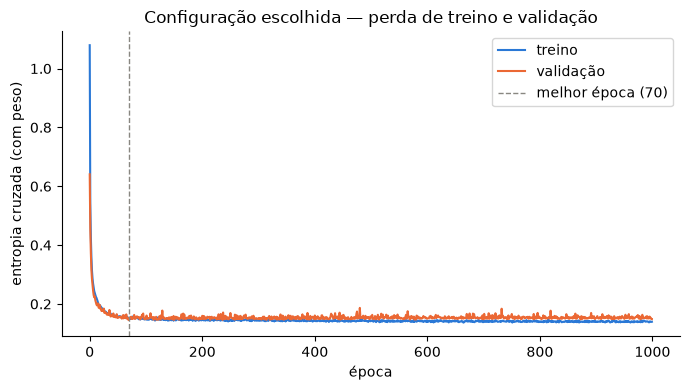

Sensibilidade por espécie (validação, média de 3 sementes):
  Myotis_lavali            0.943
  Molossus_molossus        0.933
  Lasiurus_blossevillii    0.971
  Neoeptesicus_furinalis   0.941
  Eumops_sp                0.997
  Molossus_currentium      0.975
  Molossops_temminckii     0.988
  Myotis_nigricans         0.983


In [13]:
modelo_final, ep_final, perdas_tr, perdas_va = treina(cfg, 0)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(perdas_tr, label="treino", color="#2a78d6")
ax.plot(perdas_va, label="validação", color="#eb6834")
ax.axvline(ep_final - 1, color="#898781", linestyle="--", linewidth=1, label=f"melhor época ({ep_final})")
ax.set_xlabel("época")
ax.set_ylabel("entropia cruzada (com peso)")
ax.set_title("Configuração escolhida — perda de treino e validação")
ax.legend()
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

r = cache[chave(cfg)]
sens = np.mean([x["sens"] for x in r], axis=0)
print("Sensibilidade por espécie (validação, média de 3 sementes):")
for e, s in zip(ordem_especies, sens):
    print(f"  {e:24s} {s:.3f}")

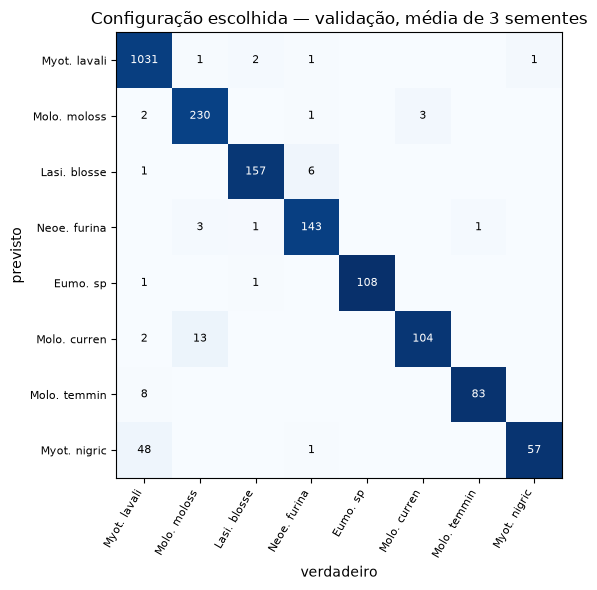

In [14]:
m = np.mean([np.array(x["matriz"]) for x in r], axis=0)
frac = m / m.sum(axis=0, keepdims=True)
curtos = [e.split("_")[0][:4] + ". " + e.split("_")[1][:6] for e in ordem_especies]
fig, ax = plt.subplots(figsize=(7, 6))
ax.imshow(frac, cmap="Blues", vmin=0, vmax=1)
for i in range(N_CLASSES):
    for j in range(N_CLASSES):
        if m[i, j] >= 0.5:
            ax.text(j, i, f"{m[i, j]:.0f}", ha="center", va="center", fontsize=8,
                    color="white" if frac[i, j] > 0.5 else "black")
ax.set_xticks(range(N_CLASSES), curtos, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(N_CLASSES), curtos, fontsize=8)
ax.set_xlabel("verdadeiro")
ax.set_ylabel("previsto")
ax.set_title("Configuração escolhida — validação, média de 3 sementes")
fig.tight_layout()
plt.show()